# Exploração textual

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/02_exploracao_textual.ipynb)

O Notebook 01 descreveu a composição e as medidas documentais da base. Agora
voltaremos ao conteúdo linguístico dos registros, começando pelas regras que
transformam texto preservado em unidades analisáveis.

## Tokenização e normalização

![O texto preservado passa por normalização, tokenização, filtro e contagem; o diagrama indica possíveis perdas em cada transformação.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/imagens/02_fluxo_tokenizacao.svg?raw=1)

Tokenizar segmenta por regra. Minúsculas, pontuação e stopwords podem apagar distinções; preserve o texto e documente decisões. Neste exemplo, os tokens são calculados separadamente por documento para não criar contextos ou n-gramas entre o fim de um texto e o início do seguinte.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_04'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente preparado em: /content/disciplina_computacao_aplicada_humanidades_digitais/unidade_04


In [2]:
import math
import re
from collections import Counter

import pandas as pd
import sys
from pathlib import Path
from IPython.display import display
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import ttr_duplo

dados = pd.read_csv("dados/documentos.csv")

def tokenizar(texto):
    return re.findall(r"[a-záàâãéêíóôõúç]+", texto.lower())

dados["tokens"] = dados["texto"].map(tokenizar)
todos_tokens = [token for documento in dados["tokens"] for token in documento]
dados[["id_documento", "tokens"]].head(2)

,id_documento,tokens
0,D001,"[a, escola, noturna, amplia, a, instrução, púb..."
1,D002,"[o, trabalho, nas, oficinas, reúne, jornada, s..."


A tokenização transforma cada documento em unidades contáveis. Como as regras
de segmentação e normalização definem o que será reconhecido como token, elas
precisam ser declaradas antes de qualquer frequência.

## Frequências absoluta e relativa

Se $t_i$ é o token na posição $i$, a frequência de uma palavra $w$ é:

$$
f(w)=\sum_{i=1}^{N}\mathbf{1}(t_i=w),
\qquad
p(w)=\frac{f(w)}{N}.
$$

O valor de $p(w)$ só é interpretável quando $N$ está declarado. Neste
experimento mostraremos dois denominadores:

| Medida | Denominador |
|---|---|
| frequência relativa entre todos os tokens | $N$, antes de retirar stopwords |
| frequência relativa entre tokens de conteúdo | $N_c$, depois de retirar stopwords |

Remover stopwords apenas da tabela, mas manter $N$ como denominador, responde a
uma pergunta diferente de recalcular a proporção dentro do vocabulário filtrado.

In [3]:
stopwords = {"a", "o", "e", "de", "do", "da", "como", "em", "nas", "um", "uma", "também"}
frequencias = Counter(todos_tokens)
tokens_conteudo = [token for token in todos_tokens if token not in stopwords]
frequencias_conteudo = Counter(tokens_conteudo)
total_tokens = len(todos_tokens)
total_tokens_conteudo = len(tokens_conteudo)

tabela_frequencias = pd.DataFrame([
    {
        "palavra": palavra,
        "frequencia": frequencia,
        "relativa_todos_tokens": frequencia / total_tokens,
        "relativa_tokens_conteudo": frequencia / total_tokens_conteudo,
    }
    for palavra, frequencia in frequencias_conteudo.most_common(12)
])
tabela_frequencias

,palavra,frequencia,relativa_todos_tokens,relativa_tokens_conteudo
0,escola,24,0.025641,0.04
1,noturna,24,0.025641,0.04
2,amplia,24,0.025641,0.04
3,instrução,24,0.025641,0.04
4,pública,24,0.025641,0.04
5,ensino,24,0.025641,0.04
6,social,24,0.025641,0.04
7,trabalho,24,0.025641,0.04
8,oficinas,24,0.025641,0.04
9,reúne,24,0.025641,0.04


As frequências mostram quanto um termo aparece, mas retiram as ocorrências de
seus contextos. Para avaliar o sentido e a relevância de uma contagem, precisamos
retornar aos documentos que a produziram.

## Concordâncias

Uma concordância recupera uma janela de $j$ tokens à esquerda e à direita de
cada ocorrência. Não é necessário transformar essa operação em uma medida única:
seu papel é devolver contexto ao agregado. As janelas devem respeitar as fronteiras
dos documentos e conservar o identificador da fonte.

In [4]:
def concordancias(tabela, alvo, janela=4):
    resultados = []
    for _, documento in tabela.iterrows():
        tokens = documento["tokens"]
        for posicao, token in enumerate(tokens):
            if token == alvo:
                inicio = max(0, posicao - janela)
                fim = min(len(tokens), posicao + janela + 1)
                resultados.append({
                    "id_documento": documento["id_documento"],
                    "contexto": " ".join(tokens[inicio:fim]),
                })
    return pd.DataFrame(resultados)

concordancias(dados, "trabalho", janela=4).head(8)

,id_documento,contexto
0,D001,o ensino social o trabalho nas oficinas reúne ...
1,D002,o trabalho nas oficinas reúne jornada
2,D002,e também conflito o trabalho nas oficinas reún...
3,D005,o ensino social o trabalho nas oficinas reúne ...
4,D005,o ensino social o trabalho nas oficinas reúne ...
5,D006,o trabalho nas oficinas reúne jornada
6,D006,e também conflito o trabalho nas oficinas reún...
7,D006,e também conflito o trabalho nas oficinas reún...


As concordâncias permitem examinar manualmente o entorno de uma palavra. O
passo seguinte sistematiza uma pergunta relacionada: quais unidades aparecem
juntas de maneira recorrente dentro dos documentos?

## N-gramas e colocações

![A frequência do bigrama é comparada às frequências marginais; o resultado deve ser examinado com frequência mínima e concordâncias.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/imagens/02_anatomia_pmi.svg?raw=1)

Um bigrama é o par adjacente $(t_i,t_{i+1})$ dentro de um mesmo documento.
Para comparar a frequência conjunta com as frequências marginais das posições
esquerda e direita, usaremos informação mútua pontual:

$$
PMI(a,b)=\log_2\left(\frac{P(a,b)}{P_L(a)P_R(b)}\right)
=\log_2\left(\frac{c(a,b)\,N_b}{c_L(a)c_R(b)}\right).
$$

| Símbolo | Significado |
|---|---|
| $c(a,b)$ | frequência do bigrama $(a,b)$ |
| $N_b$ | total de bigramas dentro dos documentos |
| $c_L(a)$ | ocorrências de $a$ na posição esquerda dos bigramas |
| $c_R(b)$ | ocorrências de $b$ na posição direita dos bigramas |

PMI alto indica associação acima do esperado pelas marginais; não indica
causalidade, importância histórica ou estabilidade. Como a medida favorece eventos
raros, exigiremos frequência mínima e retornaremos às concordâncias.

In [5]:
bigramas = Counter()
marginal_esquerda = Counter()
marginal_direita = Counter()

for tokens_documento in dados["tokens"]:
    pares_documento = list(zip(tokens_documento, tokens_documento[1:]))
    bigramas.update(pares_documento)
    marginal_esquerda.update(a for a, _ in pares_documento)
    marginal_direita.update(b for _, b in pares_documento)

total_bigramas = sum(bigramas.values())
frequencia_minima = 3
linhas_pmi = []
for (a, b), frequencia in bigramas.items():
    if frequencia >= frequencia_minima:
        pmi = math.log2(
            frequencia * total_bigramas
            / (marginal_esquerda[a] * marginal_direita[b])
        )
        linhas_pmi.append((f"{a} {b}", frequencia, pmi))

tabela_colocacoes = pd.DataFrame(
    sorted(linhas_pmi, key=lambda linha: linha[2], reverse=True),
    columns=["bigrama", "frequencia", "pmi"],
)
tabela_colocacoes.head(10)

,bigrama,frequencia,pmi
0,escola noturna,24,5.247928
1,noturna amplia,24,5.247928
2,instrução pública,24,5.247928
3,ensino social,24,5.247928
4,trabalho nas,24,5.247928
5,nas oficinas,24,5.247928
6,oficinas reúne,24,5.247928
7,reúne jornada,24,5.247928
8,jornada salário,24,5.247928
9,máquina anunciam,24,5.247928


N-gramas e PMI observam relações locais entre palavras. Agora mudaremos a
escala: em vez de pares de tokens, compararemos o repertório lexical de documentos
inteiros e verificaremos como o tamanho textual interfere nessa comparação.

## Vocabulário e diversidade lexical

Se $V_d$ é o número de formas distintas e $N_d$ o número de tokens do
documento $d$, a razão forma–token é:

$$
TTR(d)=\frac{V_d}{N_d}.
$$

Como a TTR tende a cair quando o texto cresce, podemos comparar segmentos de
tamanho fixo $m$:

$$
TTR_m(d)=\frac{\left|\{t_1,\ldots,t_m\}\right|}{m},
\qquad N_d\geq m.
$$

Para que todos os 24 documentos participem, adotaremos como $m$ o tamanho do
menor texto da base. Usar os primeiros $m$ tokens controla o tamanho, mas ainda é
sensível à posição do trecho; projetos reais devem comparar segmentos ou amostras
com um protocolo explícito.

Tamanho comum adotado: 19 tokens


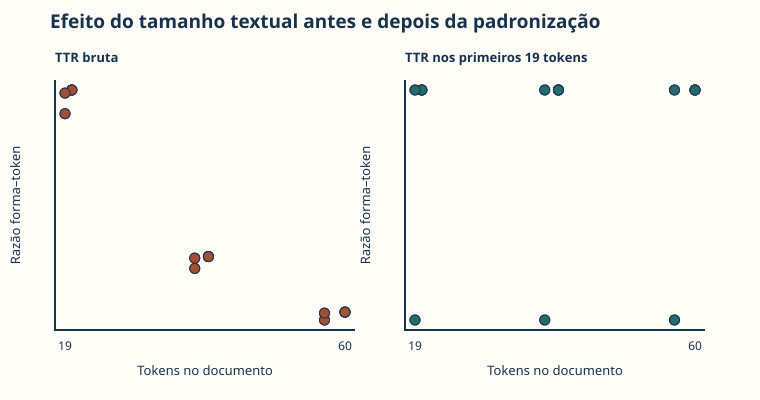

,id_documento,tokens,formas,ttr,ttr_19
0,D001,20,17,0.850000,0.842105
1,D002,38,16,0.421053,0.842105
2,D003,57,15,0.263158,0.789474
3,D004,20,17,0.850000,0.842105
4,D005,40,17,0.425000,0.842105


In [6]:
tamanho_padrao = int(dados["tokens"].map(len).min())

def ttr_padronizada(tokens, tamanho):
    if len(tokens) < tamanho:
        return pd.NA
    segmento = tokens[:tamanho]
    return len(set(segmento)) / tamanho

diversidade = pd.DataFrame({
    "id_documento": dados["id_documento"],
    "tokens": dados["tokens"].map(len),
    "formas": dados["tokens"].map(lambda tokens: len(set(tokens))),
    "ttr": dados["tokens"].map(lambda tokens: len(set(tokens)) / len(tokens)),
    f"ttr_{tamanho_padrao}": dados["tokens"].map(
        lambda tokens: ttr_padronizada(tokens, tamanho_padrao)
    ),
})
print("Tamanho comum adotado:", tamanho_padrao, "tokens")

display(ttr_duplo(
    diversidade["tokens"].tolist(),
    diversidade["ttr"].tolist(),
    diversidade[f"ttr_{tamanho_padrao}"].tolist(),
    tamanho_padrao,
))
diversidade.head()

A diversidade lexical completa um percurso que começou na representação do
texto, passou pelas contagens e retornou ao contexto. A atividade reúne essas
camadas para selecionar resultados que poderão ser comunicados visualmente sem
perder as regras que os produziram.

## U04-A03 — Atividade — exploração textual

Documente regras, frequências, concordâncias, n-gramas, colocação e diversidade.
Retorne a trechos e indique quais resultados seguirão para o Notebook 03.


### 1. Regras de Processamento Textual
* **Normalização e Tokenização:** Conversão para minúsculas via `.lower()`, remoção de pontuação/números e segmentação por palavras com a expressão regular `r"[a-záàâãéêíóôõúç]+"`.
* **Escopo:** Tokenização aplicada individualmente por documento para evitar a criação de n-gramas e contextos falsos na junção de arquivos.

---

### 2. Frequências Absolutas e Relativas
* **Frequência Absoluta ($f(w)$):** Contagem bruta de ocorrências da palavra-alvo no documento/corpus.
* **Frequência Relativa ($p(w)$):**
  * **Sobre todos os tokens ($N$):** $p(w) = \frac{f(w)}{N}$, considerando a extensão total do texto.
  * **Sobre tokens de conteúdo ($N_c$):** $p(w) = \frac{f(w)}{N_c}$, recalculada após a remoção da lista de *stopwords*.

---

### 3. Concordâncias (KWIC)
* **Janela Contextual:** Extração de $j = 5$ tokens à esquerda e à direita da palavra-alvo para inspecionar os cenários de uso.
* **Retorno aos Trechos:** Leitura direta das janelas de texto recuperadas para identificar a variação de sentidos e associar o termo ao seu contexto sintático imediato.

---

### 4. N-gramas e Colocação (PMI)
* **Filtro:** Exigência de frequência mínima do bigrama ($c(a,b) \ge \text{limiar}$) para evitar distorções de PMI em ocorrências raras.
* **Métrica:** $PMI(a,b) = \log_2\left(\frac{c(a,b) N_b}{c_L(a) c_R(b)}\right)$, identificando palavras que ocorrem juntas acima do esperado por chance.

---

### 5. Diversidade Lexical (TTR)
* **TTR Bruta:** $TTR = \frac{V}{N}$ (medida sensível ao tamanho do texto, que tende a cair em documentos mais longos).
* **TTR Padronizada ($TTR_m$):** Calculada sobre um segmento fixo de $m$ tokens em todos os documentos, neutralizando a variação provocada pela extensão textual.

---

### 6. Resultados para o Notebook 03
1. **Série Temporal de Frequência Relativa:** Gráfico de linhas da taxa da palavra-alvo por 1.000 palavras ao longo do tempo.
2. **Comparativo TTR vs. $TTR_m$:** Gráfico de dispersão contrastando a diversidade lexical bruta com a padronizada.
3. **Mapeamento de Colocações:** Gráfico de barras com os maiores valores de PMI calculados para a palavra-alvo.